In [1]:
from skyfield.api import load, wgs84
import numpy as np
from numpy import array2string
from datetime import datetime, timedelta
import pytz
from scipy import io as sio
from matplotlib import pyplot as plt
from scipy.optimize import minimize
from tqdm import tqdm
import satfunc

c = 299792458.0 # speed of light in m/s
fc = 11.575e9 # carrier frequency in Hz
f = 0.2e1 # narrowband tone freq in Hz
lo = 9.75e9 # local oscillator frequency in Hz
fs = 1e0 # sampling frequency in Hz
lam = c/fc # wavelength in m
d = lam*2 # antenna spacing in m
num_ant = 4 # number of antennas
re = 6378e3 # earth radius in m
min_elevation = 60 # minimum elevation of visible sats

In [2]:
# Load tle from path

# change the path
# path = '/Users/ishani/UIUC/Research/starlink_ofdm/AoA_Sim/tles/11_5/STARLINK-5718.tle'
path = 'D:\\Desktop\\study\\2023_summer\\starlink_ofdm\\AoA_Sim\\tles\\11_5\\STARLINK-5718.tle'

satellites = load.tle_file(path)

# % assume we have 4 synchronized LNBs, placed in the following way:
#  ------------         N
# | LNB4 LNB2 |       W + E
# | LNB3 LNB1 |         S
#  ------------
# initialize location of 4 LNBs with lat, lon = +40.11389690596162, -88.22484814695467 (UIUC)

lat_1, lon_1 = +40.11389690596162, -88.22484814695467
lnb_1 = wgs84.latlon(lat_1, lon_1)
lnb_2 = wgs84.latlon(lat_1+np.rad2deg(d/re), lon_1)
lnb_3 = wgs84.latlon(lat_1, lon_1-np.rad2deg(d/re)/np.cos(np.deg2rad(lat_1)))
lnb_4 = wgs84.latlon(lat_1+np.rad2deg(d/re), lon_1-np.rad2deg(d/re)/np.cos(np.deg2rad(lat_1)))
lnbs = [lnb_1, lnb_2, lnb_3, lnb_4]

# set start time and stop time, add 5 hours to account for time zone difference
ts = load.timescale()
start_time = datetime(2023, 11, 5, 0, 0, 0, tzinfo=pytz.UTC)+timedelta(hours=5) 
stop_time = datetime(2023, 11, 5, 0, 1, 0, tzinfo=pytz.UTC)+timedelta(hours=5)
# generate signal
received_sig, el_gt, az_gt, t_list = satfunc.gen_rx_signal(satellites[0], lnbs, start_time, stop_time, fs, fc, f)

100%|██████████| 60/60 [00:00<00:00, 641.76it/s]


- when $d=\lambda/2$, $\delta \phi_1 \in [-\pi, \pi]$.
- when $d=\lambda$, $\delta \phi_1 \in [-2\pi, 2\pi]$, while `np.angle` only returns $(-\pi, \pi]$, thus the real $\delta \phi_1$ might be $angle(r_0/r_1)$ or $angle(r_0/r_1)\pm 2\pi$.
  
In fact, for arbitrary $d$, \# of ambiguity = $\frac{d}{\lambda/2}$, $\delta \phi \in [-2\pi\times(\frac{d}{\lambda}), 2\pi\times(\frac{d}{\lambda})]$

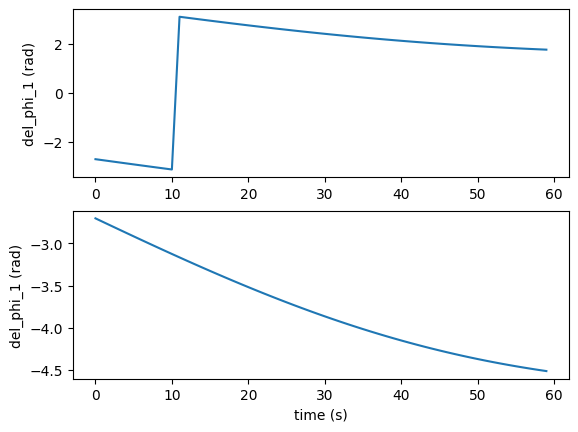

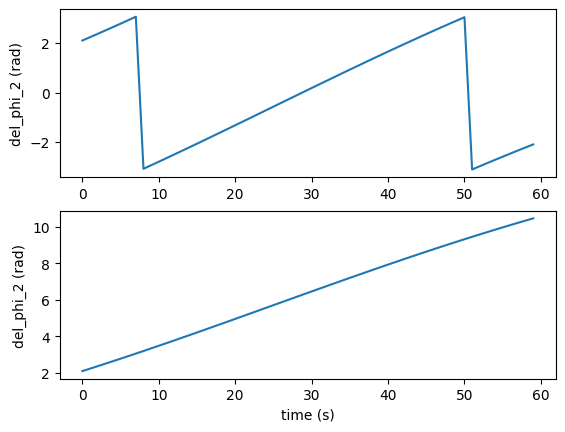

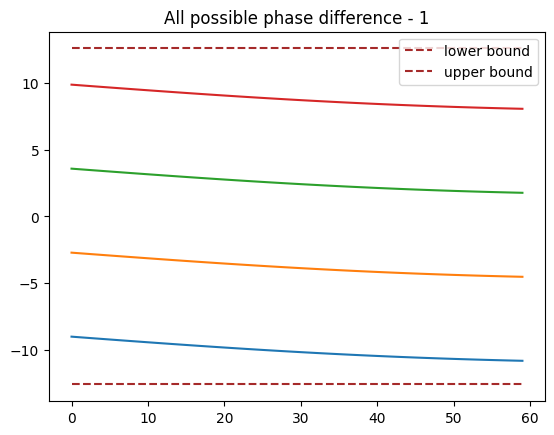

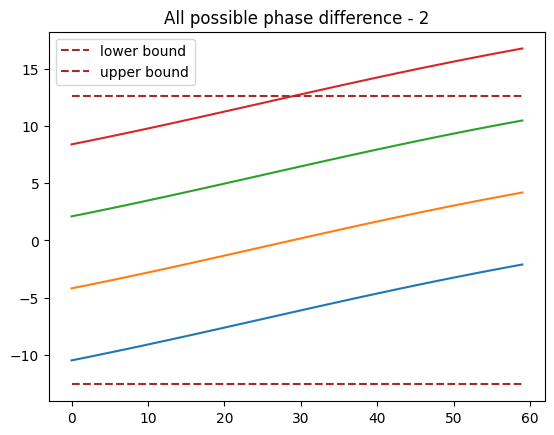

In [3]:
num_ambiguity_1d = int(d/(lam/2))
del_phi_1 = np.zeros((num_ambiguity_1d, received_sig.shape[1]))
del_phi_2 = np.zeros((num_ambiguity_1d, received_sig.shape[1]))
pattern_1 = np.unwrap(np.angle(received_sig[0,:]/received_sig[1,:]))
pattern_2 = np.unwrap(np.angle(received_sig[0,:]/received_sig[2,:]))
phi_bound = np.pi*num_ambiguity_1d

plt.figure()
plt.subplot(2,1,1)
plt.plot(t_list, np.angle(received_sig[0,:]/received_sig[1,:]))
plt.ylabel('del_phi_1 (rad)')
plt.subplot(2,1,2)
plt.plot(t_list, pattern_1)
plt.xlabel('time (s)')
plt.ylabel('del_phi_1 (rad)')
plt.show()

plt.figure()
plt.subplot(2,1,1)
plt.plot(t_list, np.angle(received_sig[0,:]/received_sig[2,:]))
plt.ylabel('del_phi_2 (rad)')
plt.subplot(2,1,2)
plt.plot(t_list, pattern_2)
plt.xlabel('time (s)')
plt.ylabel('del_phi_2 (rad)')
plt.show()
# calculate all possible delta_phis
for i in range(num_ambiguity_1d):
    del_phi_1[i, :] = pattern_1 + 2*np.pi*(i-num_ambiguity_1d//2)
if pattern_1[0] < 0:
    del_phi_1 = del_phi_1 + 2*np.pi
plt.figure()
for i in range(num_ambiguity_1d):
    plt.plot(t_list, del_phi_1[i, :])
plt.hlines(-phi_bound, t_list[0], t_list[-1], linestyles='dashed', colors='brown', label='lower bound')
plt.hlines(phi_bound, t_list[0], t_list[-1], linestyles='dashed', colors='brown', label='upper bound')
plt.legend()
plt.title('All possible phase difference - 1')
plt.show()

for i in range(num_ambiguity_1d):
    del_phi_2[i, :] = pattern_2 + 2*np.pi*(i-num_ambiguity_1d//2)
if pattern_2[0] < 0:
    del_phi_2 = del_phi_2 + 2*np.pi
plt.figure()
for i in range(num_ambiguity_1d):
    plt.plot(t_list, del_phi_2[i, :])
plt.hlines(-np.pi*num_ambiguity_1d, t_list[0], t_list[-1], linestyles='dashed', colors='brown', label='lower bound')
plt.hlines(np.pi*num_ambiguity_1d, t_list[0], t_list[-1], linestyles='dashed', colors='brown', label='upper bound')
plt.legend()
plt.title('All possible phase difference - 2')
plt.show()

Number of del_phi_1 ambiguities: 4
Number of del_phi_2 ambiguities: 3


C:\Users\User\AppData\Local\Temp\ipykernel_9872\3558092569.py:18: RuntimeWarning: invalid value encountered in arccos
  el_ = np.arccos(-del_phi_1_valid[i, :]*lam/(2*np.pi*d*np.cos(az_)))


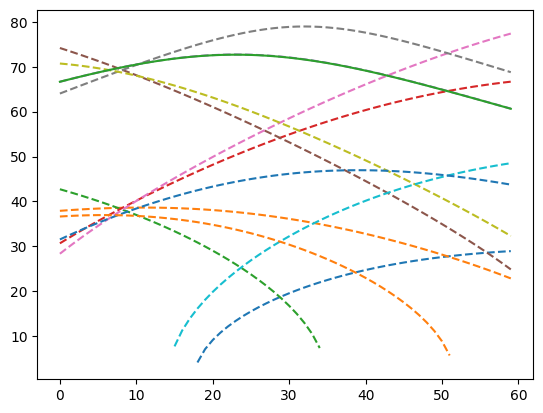

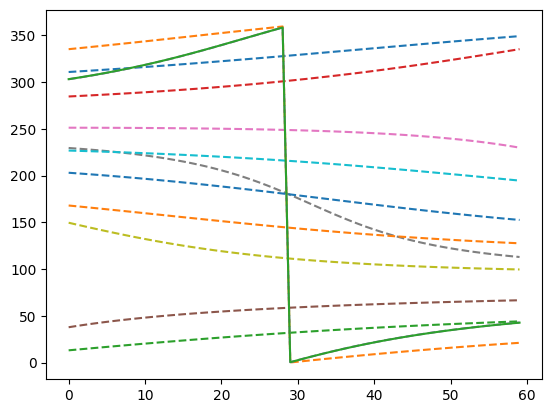

In [4]:
# calculate AoA
# first check which del_phi exceeds the bounds, exclude those
del_phi_1_valid_idx = (np.max(del_phi_1, axis=1) < phi_bound) & (np.min(del_phi_1, axis=1) > -phi_bound)
del_phi_2_valid_idx = (np.max(del_phi_2, axis=1) < phi_bound) & (np.min(del_phi_2, axis=1) > -phi_bound)
del_phi_1_valid = del_phi_1[del_phi_1_valid_idx, :]
del_phi_2_valid = del_phi_2[del_phi_2_valid_idx, :]
num_ambiguity_2d = len(del_phi_1_valid) * len(del_phi_2_valid)
print('Number of del_phi_1 ambiguities: '+str(len(del_phi_1_valid)))
print('Number of del_phi_2 ambiguities: '+str(len(del_phi_2_valid)))

phi, az, el = np.zeros((num_ambiguity_2d, len(t_list))), np.zeros((num_ambiguity_2d, len(t_list))), np.zeros((num_ambiguity_2d, len(t_list)))
for i in range(len(del_phi_1_valid)):
    for j in range(len(del_phi_2_valid)):
        phi_ = np.arctan2(-del_phi_2_valid[j, :], -del_phi_1_valid[i, :])
        phi_ = np.mod(phi_, 2*np.pi)
        az_ = 2*np.pi-phi_
        # elevation
        el_ = np.arccos(-del_phi_1_valid[i, :]*lam/(2*np.pi*d*np.cos(az_)))
        az[i*len(del_phi_2_valid)+j, :] = az_
        el[i*len(del_phi_2_valid)+j, :] = el_

plt.figure()
for i in range(num_ambiguity_2d):
    plt.plot(t_list, np.degrees(el[i, :]), linestyle='dashed', label='ambiguity '+str(i))
plt.plot(t_list, el_gt, label='ground truth')
# plt.legend()
plt.figure()
for i in range(num_ambiguity_2d):
    plt.plot(t_list, np.degrees(az[i, :]), linestyle='dashed', label='ambiguity '+str(i))
plt.plot(t_list, az_gt, label='ground truth')
# plt.legend()

In [5]:
# export del_phi_1, del_phi_2, el_gt, az_gt, t_list to .mat
sio.savemat('ambiguity_sim.mat', {'del_phi_1': del_phi_1, 'del_phi_2': del_phi_2, 'el_gt': el_gt, 'az_gt': az_gt, 'el': el, 'az': az, 't_list': t_list})

In [25]:
# Function to calculate the difference between observed and calculated azimuth and altitude
def difference(params, satellite, gt_azimuth, gt_elevation, t):
    observer = wgs84.latlon(params[0], params[1])
    dist = (satellite-observer).at(t)
    alt, az, _ = dist.altaz()
    return np.linalg.norm([alt.degrees-gt_elevation, az.degrees-gt_azimuth])

# Initial guess for observer's latitude and longitude
lat_est, lon_est = np.empty((num_ambiguity_2d, len(t_list))), np.empty((num_ambiguity_2d, len(t_list)))

for i in range(len(del_phi_1_valid)):
    for j in range(len(del_phi_2_valid)):
        initial_guess = [lat_1-1, lon_1+1]
        bounds = [(-89.9, 89.9), (-179.9, 179.9)]
        t = ts.utc(start_time)
        
        n_list = np.arange(len(t_list))
        for n in tqdm(n_list):
            result = minimize(difference, initial_guess, args=(satellites[0], np.rad2deg(az[i*len(del_phi_2_valid)+j, n]), np.rad2deg(el[i*len(del_phi_2_valid)+j, n]), t), method='L-BFGS-B', bounds=bounds)
            lat_est[i*len(del_phi_2_valid)+j, n], lon_est[i*len(del_phi_2_valid)+j, n] = result.x
            initial_guess = result.x
            # if np.abs(lat_est[n]-lat_1) > 0.1 or np.abs(lon_est[n]-lon_1) > 0.1:
            #     print(f"Estimated Latitude: {lat_est[n]}, Estimated Longitude: {lon_est[n]}")
            t = ts.utc(t.utc_datetime()+timedelta(milliseconds=1000/fs))

        # satfunc.visual_loc_result(lon_est, lat_est, lon_1, lat_1)

100%|██████████| 60/60 [00:04<00:00, 13.18it/s]


Localization Error = 728687.13 meters
Localization Error = 3940394.13 meters
Localization Error = 1184298.54 meters
Localization Error = 356758.77 meters
Localization Error = 453.65 meters
Localization Error = 375220.94 meters
Localization Error = 464182.91 meters
Localization Error = 274787.53 meters
Localization Error = 452691.05 meters
Localization Error = 681904.79 meters
Localization Error = 682360.58 meters
Localization Error = 1168801.57 meters


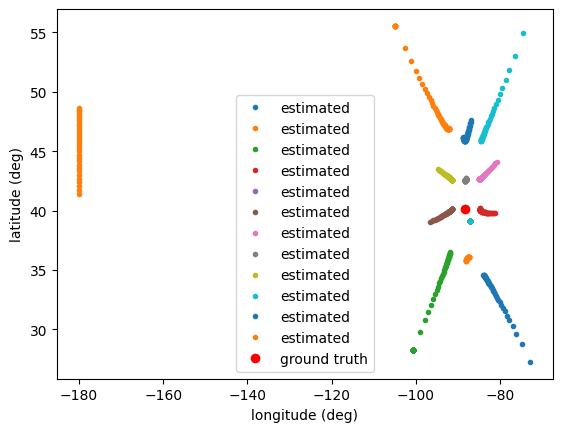

In [26]:
for i in range(num_ambiguity_2d):
    satfunc.visual_loc_result(lon_est[i, :], lat_est[i, :], lon_1, lat_1)
plt.plot(lon_1, lat_1, 'ro', label='ground truth')
plt.legend()
# save localizations to .mat
sio.savemat('../matlab_code/ambiguity_sim.mat', {'del_phi_1': del_phi_1, 'del_phi_2': del_phi_2, 'el_gt': el_gt, 'az_gt': az_gt, 'el': el, 'az': az, 't_list': t_list, 'lat_est': lat_est, 'lon_est': lon_est, 'lat_1': lat_1, 'lon_1': lon_1})

Mean elevation error:  0.03128072062312254
Mean azimuth error:  0.08236211007472789


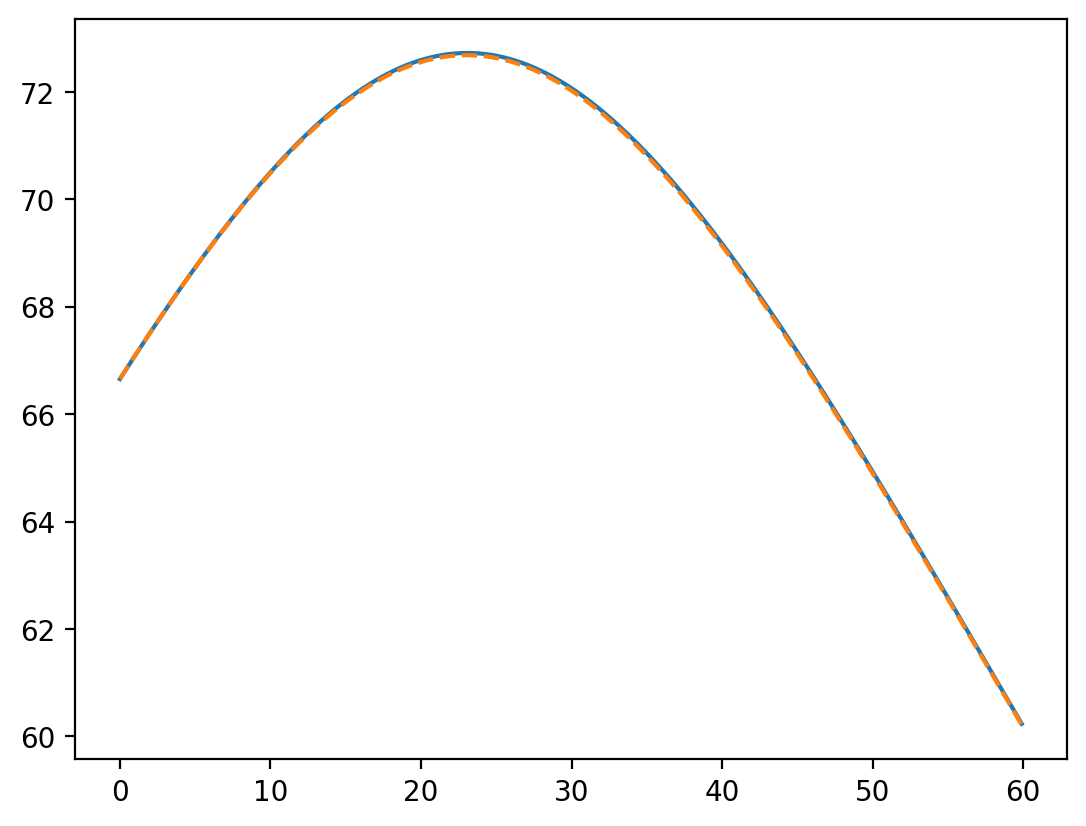

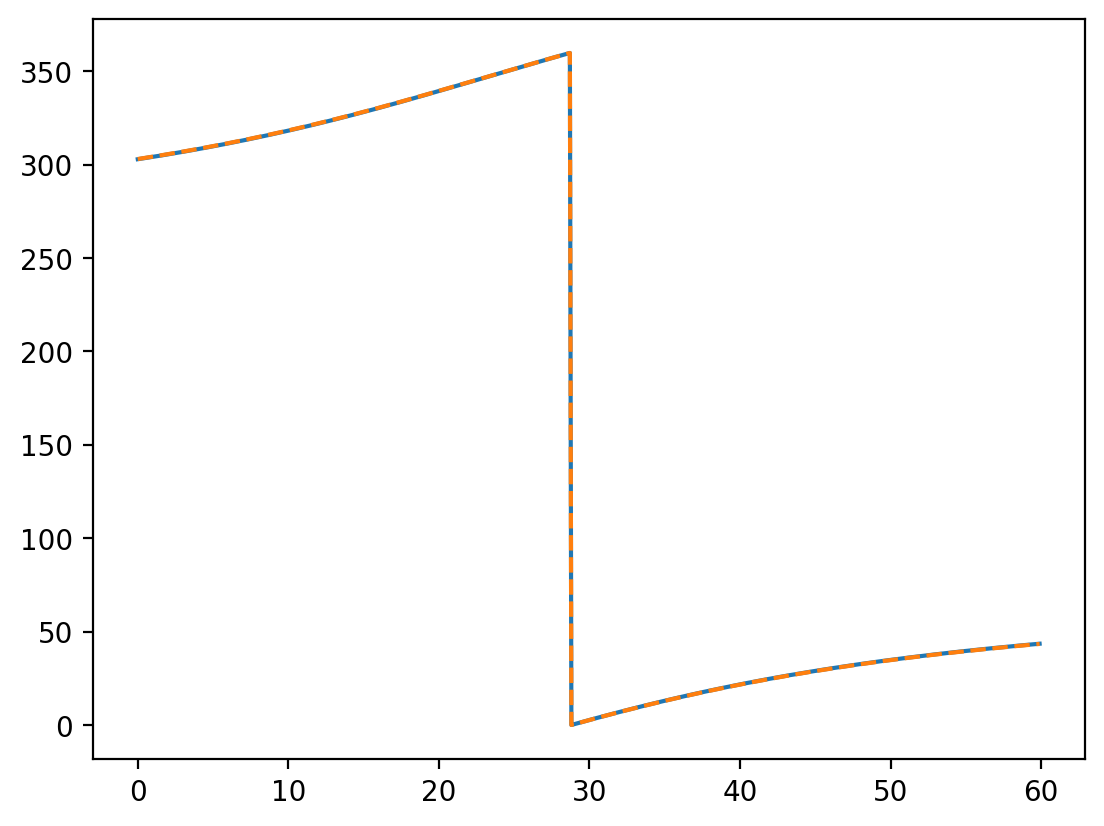

In [33]:
del_phi_1 = np.angle(received_sig[0,:]/received_sig[1,:])
del_phi_2 = np.angle(received_sig[0,:]/received_sig[2,:])

# azimuth
phi = np.arctan2(-del_phi_2, -del_phi_1)
phi = np.mod(phi, 2*np.pi)
az = 2*np.pi-phi
# elevation
el = np.arccos(-del_phi_1*lam/(2*np.pi*d*np.cos(az)))

plt.figure()
plt.plot(t_list, np.degrees(el))
plt.plot(t_list, el_gt, linestyle='--')
plt.figure()
plt.plot(t_list, np.degrees(az))
plt.plot(t_list, az_gt, linestyle='--')
# calcualte the mean error between the ground truth and estimated angles
mean_el_error = np.mean(np.abs(np.degrees(el)-el_gt))
mean_az_error = np.mean(np.abs(np.degrees(az)-az_gt))
print('Mean elevation error: ', mean_el_error)
print('Mean azimuth error: ', mean_az_error)

In [14]:
import scipy
my_var = {'el_est': el, 'az_est': az, 'el': el_gt, 'az': az_gt}
scipy.io.savemat('AoA.mat', {'my_var': my_var})

In [27]:
import scipy
my_var = {'t': t_list, 'sig': received_sig}
scipy.io.savemat('sig.mat', {'my_var': my_var})